In [1]:
import os
import shutil
import glob

os.makedirs("../data", exist_ok=True)

for f in glob.glob("*.csv"):
    shutil.copy(f, os.path.join("../data", os.path.basename(f)))

print(os.listdir("../data"))

['prices_close.csv', 'prices_high.csv', 'prices_returns.csv', 'groups.csv', 'prices_low.csv', 'prices_volume.csv', 'prices_open.csv']


In [2]:
# =====================================================================
# Part I - Finance - TEMPLATE
# =====================================================================
# The framework (finance_toolkit) fixes two things for everyone: how
# the data is loaded, and how a score panel is scored into a PnL,
# Sharpe and turnover.  Everything in the middle is yours.
#
# THE FLOW:
#   1. data is loaded for you (same for the whole class),
#   2. YOU build a SUPERSET of named features (FREE 1),
#   3. YOU write ONE recipe build_alpha(config) (FREE 2): a config
#      (feature subset, model, hyperparams) -> a trained model ->
#      scores -> positions -> its daily PnL,
#   4. YOU loop that recipe over MANY configs (FREE 3) to make many alphas,
#   5. the framework evaluates every alpha (Sharpe, turnover, ...),
#      shows the correlation between them, and keeps the best
#      un-correlated set.
#
# Your model only has to satisfy the MODEL CONTRACT:
#
#     model.predict(feat_t) -> scores
#     feat_t : float tensor (days, stocks, features)
#     scores : float tensor (days, stocks)
#
# Everything is a "panel": a table of shape (days x stocks).  Every
# operator takes panels and returns a panel of the same shape.

In [3]:
import pandas as pd
import glob

for file in glob.glob("prices_*.csv"):
    df = pd.read_csv(file)

    df["Date"] = pd.to_datetime(
        df["Date"],
        format="mixed",
        dayfirst=True
    )

    df["Date"] = df["Date"].dt.strftime("%Y-%m-%d")
    df.to_csv(file, index=False)

print("Dates corrigées ✅")

Dates corrigées ✅


In [4]:
import os
import json
import numpy
import torch
import financial_toolkit as toolkit

# =====================================================================
# FIXED 1
# =====================================================================

SEED = 42
torch.manual_seed(SEED)
numpy.random.seed(SEED)
torch.set_num_threads(4)

# Tous les fichiers sont directement dans Colab
DATA_DIR = "."

# Chargement des données
panels = toolkit.load_prices(DATA_DIR)

# Target
forward_returns = toolkit.forward_return(panels["returns"])

# Masque des actions tradables
mask = toolkit.valid_mask(panels, min_history=60)

# Dates et tickers
all_dates = panels["close"].index
tickers = panels["close"].columns

print(
    "panel:",
    panels["close"].shape,
    "dates",
    all_dates.min().date(),
    "to",
    all_dates.max().date()
)

# Split train / test
SPLIT_DATE = "2020-01-01"

is_train = all_dates < SPLIT_DATE
is_test = ~is_train

print(
    "train days:",
    int(is_train.sum()),
    "test days:",
    int(is_test.sum())
)

# Panels
close = panels["close"]
open_ = panels["open"]
high = panels["high"]
low = panels["low"]
volume = panels["volume"]
returns = panels["returns"]

# Groupes
sector, industry = toolkit.load_groups("groups.csv")

panel: (2669, 2994) dates 2013-01-02 to 2023-06-30
train days: 1775 test days: 894


In [5]:
# =====================================================================
# >>> FREE 1 <<<   FEATURES
# =====================================================================

def make_all_features(p):

    ret = p["returns"]
    close = p["close"]
    open_ = p["open"]
    high = p["high"]
    low = p["low"]
    volume = p["volume"]

    features = {}

    eps = 1e-8

    # =================================================================
    # 1. SHORT-TERM RETURN / REVERSAL
    # =================================================================

    features["ret_1d"] = toolkit.cs_zscore(
        ret, sector
    )

    features["reversal_2"] = toolkit.cs_zscore(
        -toolkit.ts_mean(ret, 2), sector
    )

    features["reversal_3"] = toolkit.cs_zscore(
        -toolkit.ts_mean(ret, 3), sector
    )

    features["reversal_5"] = toolkit.cs_zscore(
        -toolkit.ts_mean(ret, 5), sector
    )


    # =================================================================
    # 2. MOMENTUM
    # =================================================================

    features["mom_5"] = toolkit.cs_zscore(
        toolkit.ts_mean(ret, 5), sector
    )

    features["mom_10"] = toolkit.cs_zscore(
        toolkit.ts_mean(ret, 10), sector
    )

    features["mom_20"] = toolkit.cs_zscore(
        toolkit.ts_mean(ret, 20), sector
    )

    features["mom_40"] = toolkit.cs_zscore(
        toolkit.ts_mean(ret, 40), sector
    )

    features["mom_60"] = toolkit.cs_zscore(
        toolkit.ts_mean(ret, 60), sector
    )


    # =================================================================
    # 3. MOMENTUM ACCELERATION
    # =================================================================

    mom_5 = toolkit.ts_mean(ret, 5)
    mom_20 = toolkit.ts_mean(ret, 20)

    features["mom_accel"] = toolkit.cs_zscore(
        mom_5 - mom_20,
        sector
    )


    # =================================================================
    # 4. VOLATILITY
    # =================================================================

    vol_5 = toolkit.ts_std(ret, 5)
    vol_10 = toolkit.ts_std(ret, 10)
    vol_20 = toolkit.ts_std(ret, 20)
    vol_60 = toolkit.ts_std(ret, 60)

    features["vol_5"] = toolkit.cs_zscore(
        vol_5, sector
    )

    features["vol_10"] = toolkit.cs_zscore(
        vol_10, sector
    )

    features["vol_20"] = toolkit.cs_zscore(
        vol_20, sector
    )

    features["vol_60"] = toolkit.cs_zscore(
        vol_60, sector
    )

    features["vol_change"] = toolkit.cs_zscore(
        vol_5 - vol_20,
        sector
    )


    # =================================================================
    # 5. VOLATILITY-ADJUSTED RETURN
    # =================================================================

    risk_adjusted_ret = ret / (vol_20 + eps)

    features["risk_adjusted_ret"] = toolkit.cs_zscore(
        risk_adjusted_ret,
        sector
    )


    # =================================================================
    # 6. INTRADAY PRICE ACTION
    # =================================================================

    intraday = (close - open_) / (open_ + eps)

    features["intraday"] = toolkit.cs_zscore(
        intraday,
        sector
    )

    features["intraday_5"] = toolkit.cs_zscore(
        toolkit.ts_mean(intraday, 5),
        sector
    )

    features["intraday_20"] = toolkit.cs_zscore(
        toolkit.ts_mean(intraday, 20),
        sector
    )


    # =================================================================
    # 7. DAILY RANGE / CLOSE POSITION
    # =================================================================

    daily_range = high - low

    range_position = (
        (close - low) /
        (daily_range + eps)
    )

    features["range_position"] = toolkit.cs_zscore(
        range_position,
        sector
    )

    features["range_position_5"] = toolkit.cs_zscore(
        toolkit.ts_mean(range_position, 5),
        sector
    )

    features["range_position_20"] = toolkit.cs_zscore(
        toolkit.ts_mean(range_position, 20),
        sector
    )


    # =================================================================
    # 8. RELATIVE DAILY RANGE
    # =================================================================

    relative_range = (
        (high - low) /
        (close + eps)
    )

    features["range_1"] = toolkit.cs_zscore(
        relative_range,
        sector
    )

    features["range_5"] = toolkit.cs_zscore(
        toolkit.ts_mean(relative_range, 5),
        sector
    )

    features["range_20"] = toolkit.cs_zscore(
        toolkit.ts_mean(relative_range, 20),
        sector
    )


    # =================================================================
    # 9. CANDLE / BUYING PRESSURE
    # =================================================================

    candle_strength = (
        (close - open_) /
        (high - low + eps)
    )

    features["candle_strength"] = toolkit.cs_zscore(
        candle_strength,
        sector
    )

    close_strength = (
        (2 * close - high - low) /
        (high - low + eps)
    )

    features["close_strength"] = toolkit.cs_zscore(
        close_strength,
        sector
    )


    # =================================================================
    # 10. VOLUME
    # =================================================================

    volume_mean_5 = toolkit.ts_mean(volume, 5)
    volume_mean_20 = toolkit.ts_mean(volume, 20)
    volume_mean_60 = toolkit.ts_mean(volume, 60)

    features["volume_ratio"] = toolkit.cs_zscore(
        volume / (volume_mean_20 + eps),
        sector
    )

    features["volume_5_20"] = toolkit.cs_zscore(
        volume_mean_5 / (volume_mean_20 + eps),
        sector
    )

    features["volume_20_60"] = toolkit.cs_zscore(
        volume_mean_20 / (volume_mean_60 + eps),
        sector
    )


    # =================================================================
    # 11. RETURN × VOLUME INTERACTION
    # =================================================================

    volume_surprise = (
        volume /
        (volume_mean_20 + eps)
    )

    features["return_volume"] = toolkit.cs_zscore(
        ret * volume_surprise,
        sector
    )


    # =================================================================
    # 12. TIME-SERIES RETURN Z-SCORE
    # =================================================================

    ret_z20 = toolkit.ts_zscore(
        ret,
        20
    )

    features["ret_z20"] = toolkit.cs_zscore(
        ret_z20,
        sector
    )


    # =================================================================
    # 13. INDUSTRY-NEUTRAL FEATURES
    # Helps create different alphas from sector-neutral versions
    # =================================================================

    features["ret_1d_industry"] = toolkit.cs_zscore(
        ret,
        industry
    )

    features["mom_20_industry"] = toolkit.cs_zscore(
        toolkit.ts_mean(ret, 20),
        industry
    )

    features["vol_20_industry"] = toolkit.cs_zscore(
        toolkit.ts_std(ret, 20),
        industry
    )

    features["range_industry"] = toolkit.cs_zscore(
        range_position,
        industry
    )


    # =================================================================
    # 14. RANK-BASED FEATURES
    # More robust to extreme observations
    # =================================================================

    features["ret_rank"] = toolkit.cs_rank(
        ret,
        sector
    )

    features["mom_20_rank"] = toolkit.cs_rank(
        toolkit.ts_mean(ret, 20),
        sector
    )

    features["vol_20_rank"] = toolkit.cs_rank(
        toolkit.ts_std(ret, 20),
        sector
    )

    features["volume_rank"] = toolkit.cs_rank(
        volume_surprise,
        sector
    )

    return features


# =====================================================================
# Build all features
# =====================================================================

all_features = make_all_features(panels)

print("Number of features:", len(all_features))
print("\nFeatures available:")

for name in sorted(all_features.keys()):
    print("-", name)

Number of features: 40

Features available:
- candle_strength
- close_strength
- intraday
- intraday_20
- intraday_5
- mom_10
- mom_20
- mom_20_industry
- mom_20_rank
- mom_40
- mom_5
- mom_60
- mom_accel
- range_1
- range_20
- range_5
- range_industry
- range_position
- range_position_20
- range_position_5
- ret_1d
- ret_1d_industry
- ret_rank
- ret_z20
- return_volume
- reversal_2
- reversal_3
- reversal_5
- risk_adjusted_ret
- vol_10
- vol_20
- vol_20_industry
- vol_20_rank
- vol_5
- vol_60
- vol_change
- volume_20_60
- volume_5_20
- volume_rank
- volume_ratio


In [6]:
# =====================================================================
# >>> FREE 2 <<<   build one alpha from a config
# =====================================================================

def build_alpha(config):

    # -------------------------------------------------
    # 1. Select features
    # -------------------------------------------------
    feature_names = config["features"]

    selected_features = {
        name: all_features[name]
        for name in feature_names
    }

    # -------------------------------------------------
    # 2. Stack features
    # -------------------------------------------------
    feature_array, feature_names = toolkit.stack_features(
        selected_features
    )

    feat_t, label_t, valid_t = toolkit.make_tensors(
        feature_array,
        forward_returns,
        mask
    )

    # -------------------------------------------------
    # 3. Create train / test datasets
    # -------------------------------------------------
    train_ds = toolkit.DayDataset(
        feat_t,
        label_t,
        valid_t,
        is_train
    )

    test_ds = toolkit.DayDataset(
        feat_t,
        label_t,
        valid_t,
        is_test
    )

    # -------------------------------------------------
    # 4. Reproducibility
    # -------------------------------------------------
    torch.manual_seed(SEED)
    numpy.random.seed(SEED)

    # -------------------------------------------------
    # 5. Build model
    # -------------------------------------------------
    model_type = config.get("model", "MLP")

    if model_type == "MLP":

        model = toolkit.MLP(
            input_size=len(feature_names),
            hidden=config.get("hidden", (16, 16)),
            dropout=config.get("dropout", 0.0)
        )

    elif model_type == "LSTM":

        model = toolkit.LSTM(
            input_size=len(feature_names),
            hidden_size=config.get("hidden_size", 8),
            num_layers=config.get("num_layers", 1),
            dropout=config.get("dropout", 0.0)
        )

    else:
        raise ValueError(
            "Unknown model type: " + str(model_type)
        )

    # -------------------------------------------------
    # 6. Train
    # -------------------------------------------------
    model, history = toolkit.train(
        model,
        train_ds,
        test_ds,
        epochs=config.get("epochs", 5),
        batch_size=config.get("batch_size", 64),
        lr=config.get("lr", 1e-3),
        weight_decay=config.get("weight_decay", 0.0),
        ir_steps=config.get("ir_steps", None),
        tvr_steps=config.get("tvr_steps", None)
    )

    # -------------------------------------------------
    # 7. Predict scores
    # -------------------------------------------------
    scores = toolkit.predict_scores(
        model,
        feat_t,
        all_dates,
        tickers
    )

    # -------------------------------------------------
    # 8. Scores -> portfolio positions
    # -------------------------------------------------
    all_positions = toolkit.scores_to_positions(
        scores,
        mask
    )

    test_positions = all_positions.loc[is_test]

    # -------------------------------------------------
    # 9. Hold-out returns
    # -------------------------------------------------
    test_forward_returns = forward_returns.loc[is_test]

    # -------------------------------------------------
    # 10. PnL
    # -------------------------------------------------
    pnl = toolkit.simulate(
        test_positions,
        test_forward_returns
    )

    # -------------------------------------------------
    # 11. Statistics
    # -------------------------------------------------
    stats = toolkit.evaluate(
        test_positions,
        test_forward_returns
    )

    print(
        "Sharpe:",
        round(stats["sharpe"], 3),
        "| Turnover:",
        round(stats["turnover"], 3)
    )

    # -------------------------------------------------
    # 12. Return everything
    # -------------------------------------------------
    return {
        "model": model,
        "features": feature_names,
        "positions": test_positions,
        "pnl": pnl,
        "stats": stats,
        "history": history
    }

In [7]:
# =====================================================================
# >>> FREE 3 <<<   DIVERSE ALPHA SEARCH
# =====================================================================

# Stronger turnover penalty
LOW_TURNOVER = [
    (0.30, 0.0),
    (0.50, 1.0),
    (numpy.inf, 4.0)
]

configs = {

    # ================================================================
    # 1. Baseline - already gave Sharpe ~2.5
    # ================================================================
    "alpha_01": {
        "features": [
            "ret_1d",
            "mom_5",
            "mom_20",
            "vol_5",
            "vol_20",
            "intraday",
            "range_position",
            "volume_ratio"
        ],
        "model": "MLP",
        "hidden": (16, 16),
        "dropout": 0.1,
        "epochs": 5,
        "lr": 1e-3,
        "weight_decay": 1e-4
    },

    # ================================================================
    # 2. Return + volatility - our strongest previous family
    # ================================================================
    "alpha_02": {
        "features": [
            "ret_1d",
            "vol_5",
            "vol_20"
        ],
        "model": "MLP",
        "hidden": (8, 16),
        "dropout": 0.1,
        "epochs": 7,
        "lr": 1e-3,
        "weight_decay": 1e-4
    },

    # ================================================================
    # 3. Short-term reversal
    # ================================================================
    "alpha_03": {
        "features": [
            "reversal_2",
            "reversal_3",
            "ret_z20"
        ],
        "model": "MLP",
        "hidden": (12, 8),
        "dropout": 0.1,
        "epochs": 7,
        "lr": 8e-4,
        "weight_decay": 1e-4,
        "tvr_steps": LOW_TURNOVER
    },

    # ================================================================
    # 4. Long-term momentum
    # ================================================================
    "alpha_04": {
        "features": [
            "mom_20",
            "mom_40",
            "mom_60",
            "vol_60"
        ],
        "model": "MLP",
        "hidden": (16, 8),
        "dropout": 0.15,
        "epochs": 7,
        "lr": 8e-4,
        "weight_decay": 5e-4,
        "tvr_steps": LOW_TURNOVER
    },

    # ================================================================
    # 5. Momentum acceleration
    # ================================================================
    "alpha_05": {
        "features": [
            "mom_accel",
            "mom_10",
            "vol_change"
        ],
        "model": "MLP",
        "hidden": (12, 8),
        "dropout": 0.1,
        "epochs": 7,
        "lr": 8e-4,
        "weight_decay": 1e-4,
        "tvr_steps": LOW_TURNOVER
    },

    # ================================================================
    # 6. Intraday behaviour
    # ================================================================
    "alpha_06": {
        "features": [
            "intraday",
            "intraday_5",
            "intraday_20",
            "candle_strength"
        ],
        "model": "MLP",
        "hidden": (16, 8),
        "dropout": 0.1,
        "epochs": 7,
        "lr": 8e-4,
        "weight_decay": 1e-4,
        "tvr_steps": LOW_TURNOVER
    },

    # ================================================================
    # 7. High-low range behaviour
    # ================================================================
    "alpha_07": {
        "features": [
            "range_position",
            "range_position_5",
            "range_position_20",
            "range_20",
            "close_strength"
        ],
        "model": "MLP",
        "hidden": (16, 8),
        "dropout": 0.1,
        "epochs": 7,
        "lr": 8e-4,
        "weight_decay": 5e-4,
        "tvr_steps": LOW_TURNOVER
    },

    # ================================================================
    # 8. Volume
    # ================================================================
    "alpha_08": {
        "features": [
            "volume_ratio",
            "volume_5_20",
            "volume_20_60",
            "return_volume"
        ],
        "model": "MLP",
        "hidden": (12, 8),
        "dropout": 0.1,
        "epochs": 7,
        "lr": 8e-4,
        "weight_decay": 5e-4,
        "tvr_steps": LOW_TURNOVER
    },

    # ================================================================
    # 9. Risk-adjusted signals
    # ================================================================
    "alpha_09": {
        "features": [
            "risk_adjusted_ret",
            "vol_change",
            "vol_10",
            "vol_60"
        ],
        "model": "MLP",
        "hidden": (12, 8),
        "dropout": 0.1,
        "epochs": 7,
        "lr": 8e-4,
        "weight_decay": 5e-4,
        "tvr_steps": LOW_TURNOVER
    },

    # ================================================================
    # 10. Industry-neutral signals
    # ================================================================
    "alpha_10": {
        "features": [
            "ret_1d_industry",
            "mom_20_industry",
            "vol_20_industry",
            "range_industry"
        ],
        "model": "MLP",
        "hidden": (16, 8),
        "dropout": 0.1,
        "epochs": 7,
        "lr": 8e-4,
        "weight_decay": 1e-4,
        "tvr_steps": LOW_TURNOVER
    },

    # ================================================================
    # 11. Rank-based robust signals
    # ================================================================
    "alpha_11": {
        "features": [
            "ret_rank",
            "mom_20_rank",
            "vol_20_rank",
            "volume_rank"
        ],
        "model": "MLP",
        "hidden": (16, 8),
        "dropout": 0.1,
        "epochs": 7,
        "lr": 8e-4,
        "weight_decay": 1e-4,
        "tvr_steps": LOW_TURNOVER
    },

    # ================================================================
    # 12. Mixed slower signal
    # ================================================================
    "alpha_12": {
        "features": [
            "mom_40",
            "vol_60",
            "intraday_20",
            "range_position_20",
            "volume_20_60"
        ],
        "model": "MLP",
        "hidden": (16, 8),
        "dropout": 0.15,
        "epochs": 7,
        "lr": 8e-4,
        "weight_decay": 5e-4,
        "tvr_steps": LOW_TURNOVER
    }
}


# =====================================================================
# TRAIN ALL ALPHAS
# =====================================================================

results = {}
trained = {}
positions = {}
alphas = {}
feature_sets = {}


for name, config in configs.items():

    print("\n" + "=" * 60)
    print("TRAINING", name)
    print("=" * 60)

    result = build_alpha(config)

    results[name] = result
    trained[name] = result["model"]
    positions[name] = result["positions"]
    alphas[name] = result["pnl"]
    feature_sets[name] = result["features"]


print("\n" + "=" * 60)
print("SEARCH FINISHED")
print("=" * 60)
print("Number of candidate alphas:", len(alphas))


TRAINING alpha_01
epoch  0 | train loss 0.70733 ir 0.0966 tvr 1.0772 | val loss 0.52894 ir 0.1034 tvr 0.9124
epoch  1 | train loss 0.49831 ir 0.1226 tvr 0.8938 | val loss 0.30692 ir 0.1230 tvr 0.7099
epoch  2 | train loss 0.34195 ir 0.1345 tvr 0.7490 | val loss 0.15981 ir 0.1390 tvr 0.5788
epoch  3 | train loss 0.22391 ir 0.1604 tvr 0.6565 | val loss 0.08772 ir 0.1466 tvr 0.5144
epoch  4 | train loss 0.16450 ir 0.1649 tvr 0.6014 | val loss 0.04799 ir 0.1526 tvr 0.4806
Sharpe: 2.625 | Turnover: 0.475

TRAINING alpha_02
epoch  0 | train loss 0.63389 ir 0.1095 tvr 1.0166 | val loss 0.19955 ir 0.1335 tvr 0.6131
epoch  1 | train loss 0.42344 ir 0.1259 tvr 0.8220 | val loss 0.08088 ir 0.1434 tvr 0.5043
epoch  2 | train loss 0.28276 ir 0.1263 tvr 0.6813 | val loss 0.00205 ir 0.1533 tvr 0.4353
epoch  3 | train loss 0.17957 ir 0.1399 tvr 0.5913 | val loss -0.02036 ir 0.1565 tvr 0.4154
epoch  4 | train loss 0.12268 ir 0.1391 tvr 0.5335 | val loss -0.02870 ir 0.1576 tvr 0.4070
epoch  5 | train l

In [8]:
# =====================================================================
# EXTRA ALPHA SEARCH -- candidates 13 to 24
# =====================================================================

extra_configs = {

    # -------------------------------------------------
    # 13. Long momentum - slightly less turnover penalty
    # alpha_04 was already close to passing
    # -------------------------------------------------
    "alpha_13": {
        "features": [
            "mom_20",
            "mom_40",
            "mom_60",
            "vol_60"
        ],
        "model": "MLP",
        "hidden": (24, 12),
        "dropout": 0.1,
        "epochs": 10,
        "lr": 5e-4,
        "weight_decay": 1e-4,
        "tvr_steps": [
            (0.40, 0.0),
            (0.65, 0.3),
            (numpy.inf, 1.5)
        ]
    },

    # -------------------------------------------------
    # 14. Long momentum + volume
    # -------------------------------------------------
    "alpha_14": {
        "features": [
            "mom_20",
            "mom_40",
            "mom_60",
            "volume_20_60"
        ],
        "model": "MLP",
        "hidden": (16, 8),
        "dropout": 0.1,
        "epochs": 9,
        "lr": 6e-4,
        "weight_decay": 1e-4,
        "tvr_steps": [
            (0.35, 0.0),
            (0.60, 0.5),
            (numpy.inf, 2.0)
        ]
    },

    # -------------------------------------------------
    # 15. Rank signals - alpha_11 was close to passing
    # -------------------------------------------------
    "alpha_15": {
        "features": [
            "ret_rank",
            "mom_20_rank",
            "vol_20_rank",
            "volume_rank"
        ],
        "model": "MLP",
        "hidden": (24, 12),
        "dropout": 0.05,
        "epochs": 10,
        "lr": 5e-4,
        "weight_decay": 1e-4,
        "tvr_steps": [
            (0.40, 0.0),
            (0.65, 0.3),
            (numpy.inf, 1.5)
        ]
    },

    # -------------------------------------------------
    # 16. Rank + risk adjusted
    # -------------------------------------------------
    "alpha_16": {
        "features": [
            "ret_rank",
            "risk_adjusted_ret",
            "vol_20_rank",
            "volume_rank"
        ],
        "model": "MLP",
        "hidden": (16, 12),
        "dropout": 0.1,
        "epochs": 9,
        "lr": 6e-4,
        "weight_decay": 1e-4,
        "tvr_steps": [
            (0.35, 0.0),
            (0.60, 0.5),
            (numpy.inf, 2.0)
        ]
    },

    # -------------------------------------------------
    # 17. Slow intraday
    # -------------------------------------------------
    "alpha_17": {
        "features": [
            "intraday_5",
            "intraday_20",
            "range_position_20",
            "vol_20"
        ],
        "model": "MLP",
        "hidden": (16, 8),
        "dropout": 0.1,
        "epochs": 9,
        "lr": 7e-4,
        "weight_decay": 1e-4,
        "tvr_steps": [
            (0.30, 0.0),
            (0.55, 0.5),
            (numpy.inf, 2.0)
        ]
    },

    # -------------------------------------------------
    # 18. Range + volume slow
    # -------------------------------------------------
    "alpha_18": {
        "features": [
            "range_5",
            "range_20",
            "range_position_20",
            "volume_20_60"
        ],
        "model": "MLP",
        "hidden": (16, 8),
        "dropout": 0.1,
        "epochs": 9,
        "lr": 6e-4,
        "weight_decay": 5e-4,
        "tvr_steps": [
            (0.30, 0.0),
            (0.55, 0.5),
            (numpy.inf, 2.0)
        ]
    },

    # -------------------------------------------------
    # 19. Volatility regime
    # -------------------------------------------------
    "alpha_19": {
        "features": [
            "vol_5",
            "vol_10",
            "vol_20",
            "vol_60",
            "vol_change"
        ],
        "model": "MLP",
        "hidden": (20, 10),
        "dropout": 0.1,
        "epochs": 9,
        "lr": 6e-4,
        "weight_decay": 1e-4,
        "tvr_steps": [
            (0.30, 0.0),
            (0.55, 0.5),
            (numpy.inf, 2.0)
        ]
    },

    # -------------------------------------------------
    # 20. Candle / close pressure
    # -------------------------------------------------
    "alpha_20": {
        "features": [
            "candle_strength",
            "close_strength",
            "intraday_5",
            "range_position_5"
        ],
        "model": "MLP",
        "hidden": (16, 8),
        "dropout": 0.1,
        "epochs": 9,
        "lr": 6e-4,
        "weight_decay": 1e-4,
        "tvr_steps": [
            (0.35, 0.0),
            (0.60, 0.5),
            (numpy.inf, 2.0)
        ]
    },

    # -------------------------------------------------
    # 21. Volume regime only
    # -------------------------------------------------
    "alpha_21": {
        "features": [
            "volume_ratio",
            "volume_5_20",
            "volume_20_60",
            "volume_rank"
        ],
        "model": "MLP",
        "hidden": (20, 10),
        "dropout": 0.05,
        "epochs": 9,
        "lr": 6e-4,
        "weight_decay": 1e-4,
        "tvr_steps": [
            (0.30, 0.0),
            (0.55, 0.5),
            (numpy.inf, 2.0)
        ]
    },

    # -------------------------------------------------
    # 22. Industry-neutral slower signals
    # -------------------------------------------------
    "alpha_22": {
        "features": [
            "mom_20_industry",
            "vol_20_industry",
            "range_industry"
        ],
        "model": "MLP",
        "hidden": (20, 10),
        "dropout": 0.1,
        "epochs": 9,
        "lr": 6e-4,
        "weight_decay": 1e-4,
        "tvr_steps": [
            (0.35, 0.0),
            (0.60, 0.5),
            (numpy.inf, 2.0)
        ]
    },

    # -------------------------------------------------
    # 23. Momentum acceleration + volume
    # -------------------------------------------------
    "alpha_23": {
        "features": [
            "mom_accel",
            "mom_10",
            "volume_5_20",
            "vol_change"
        ],
        "model": "MLP",
        "hidden": (16, 8),
        "dropout": 0.1,
        "epochs": 9,
        "lr": 6e-4,
        "weight_decay": 1e-4,
        "tvr_steps": [
            (0.30, 0.0),
            (0.55, 0.5),
            (numpy.inf, 2.0)
        ]
    },

    # -------------------------------------------------
    # 24. Slow diversified signal
    # -------------------------------------------------
    "alpha_24": {
        "features": [
            "mom_40",
            "intraday_20",
            "range_position_20",
            "volume_20_60",
            "vol_60"
        ],
        "model": "MLP",
        "hidden": (20, 10),
        "dropout": 0.1,
        "epochs": 10,
        "lr": 5e-4,
        "weight_decay": 5e-4,
        "tvr_steps": [
            (0.30, 0.0),
            (0.55, 0.5),
            (numpy.inf, 2.0)
        ]
    }
}


# =====================================================================
# Train and ADD them to the existing dictionaries
# =====================================================================

for name, config in extra_configs.items():

    print("\n" + "=" * 60)
    print("TRAINING", name)
    print("=" * 60)

    result = build_alpha(config)

    results[name] = result
    trained[name] = result["model"]
    positions[name] = result["positions"]
    alphas[name] = result["pnl"]
    feature_sets[name] = result["features"]


print("\n" + "=" * 60)
print("EXTRA SEARCH FINISHED")
print("=" * 60)

print("Total candidate alphas:", len(alphas))


TRAINING alpha_13
epoch  0 | train loss 0.42621 ir 0.0410 tvr 0.8929 | val loss 0.04265 ir -0.0356 tvr 0.3673
epoch  1 | train loss 0.36062 ir -0.0089 tvr 0.8157 | val loss 0.07811 ir -0.0732 tvr 0.3526
epoch  2 | train loss 0.25213 ir 0.0125 tvr 0.7572 | val loss 0.04137 ir -0.0413 tvr 0.2932
epoch  3 | train loss 0.20431 ir 0.0095 tvr 0.7159 | val loss 0.06035 ir -0.0503 tvr 0.3733
epoch  4 | train loss 0.19038 ir 0.0031 tvr 0.6930 | val loss 0.04120 ir -0.0412 tvr 0.2793
epoch  5 | train loss 0.17244 ir 0.0095 tvr 0.6804 | val loss 0.03815 ir -0.0381 tvr 0.2793
epoch  6 | train loss 0.13654 ir 0.0365 tvr 0.6688 | val loss 0.03855 ir -0.0385 tvr 0.2858
epoch  7 | train loss 0.13249 ir 0.0324 tvr 0.6590 | val loss 0.03037 ir -0.0304 tvr 0.2756
epoch  8 | train loss 0.11817 ir 0.0374 tvr 0.6466 | val loss 0.02699 ir -0.0260 tvr 0.3285
epoch  9 | train loss 0.11245 ir 0.0342 tvr 0.6360 | val loss 0.00558 ir -0.0044 tvr 0.3132
Sharpe: -0.18 | Turnover: 0.356

TRAINING alpha_14
epoch  0 

In [9]:
# =====================================================================
# FINAL TARGETED SEARCH -- alpha 25 to 32
# =====================================================================
import numpy

FINAL_TVR = [
    (0.30, 0.0),
    (0.50, 0.5),
    (numpy.inf, 2.0)
]

final_configs = {

    # -------------------------------------------------
    # 25. Pure volume - very different family
    # -------------------------------------------------
    "alpha_25": {
        "features": [
            "volume_ratio",
            "volume_5_20",
            "volume_20_60"
        ],
        "model": "MLP",
        "hidden": (24, 12),
        "dropout": 0.05,
        "epochs": 12,
        "lr": 5e-4,
        "weight_decay": 1e-4,
        "tvr_steps": FINAL_TVR
    },

    # -------------------------------------------------
    # 26. Volume + range
    # -------------------------------------------------
    "alpha_26": {
        "features": [
            "volume_ratio",
            "volume_rank",
            "range_position_5",
            "range_20"
        ],
        "model": "MLP",
        "hidden": (20, 10),
        "dropout": 0.05,
        "epochs": 10,
        "lr": 6e-4,
        "weight_decay": 1e-4,
        "tvr_steps": FINAL_TVR
    },

    # -------------------------------------------------
    # 27. Candle / price pressure
    # -------------------------------------------------
    "alpha_27": {
        "features": [
            "candle_strength",
            "close_strength",
            "range_position",
            "intraday"
        ],
        "model": "MLP",
        "hidden": (24, 12),
        "dropout": 0.05,
        "epochs": 10,
        "lr": 5e-4,
        "weight_decay": 1e-4,
        "tvr_steps": FINAL_TVR
    },

    # -------------------------------------------------
    # 28. Slow price pressure
    # -------------------------------------------------
    "alpha_28": {
        "features": [
            "intraday_20",
            "range_position_20",
            "range_20",
            "volume_20_60"
        ],
        "model": "MLP",
        "hidden": (24, 12),
        "dropout": 0.05,
        "epochs": 12,
        "lr": 5e-4,
        "weight_decay": 1e-4,
        "tvr_steps": FINAL_TVR
    },

    # -------------------------------------------------
    # 29. Industry + volume
    # -------------------------------------------------
    "alpha_29": {
        "features": [
            "ret_1d_industry",
            "mom_20_industry",
            "volume_ratio",
            "volume_20_60"
        ],
        "model": "MLP",
        "hidden": (20, 10),
        "dropout": 0.05,
        "epochs": 10,
        "lr": 5e-4,
        "weight_decay": 1e-4,
        "tvr_steps": FINAL_TVR
    },

    # -------------------------------------------------
    # 30. Industry + risk
    # -------------------------------------------------
    "alpha_30": {
        "features": [
            "mom_20_industry",
            "vol_20_industry",
            "risk_adjusted_ret",
            "range_industry"
        ],
        "model": "MLP",
        "hidden": (20, 10),
        "dropout": 0.05,
        "epochs": 10,
        "lr": 5e-4,
        "weight_decay": 1e-4,
        "tvr_steps": FINAL_TVR
    },

    # -------------------------------------------------
    # 31. Rank + volume
    # -------------------------------------------------
    "alpha_31": {
        "features": [
            "ret_rank",
            "volume_rank",
            "range_position_5",
            "intraday_5"
        ],
        "model": "MLP",
        "hidden": (20, 10),
        "dropout": 0.05,
        "epochs": 10,
        "lr": 5e-4,
        "weight_decay": 1e-4,
        "tvr_steps": FINAL_TVR
    },

    # -------------------------------------------------
    # 32. Mixed slow independent candidate
    # -------------------------------------------------
    "alpha_32": {
        "features": [
            "mom_60",
            "vol_change",
            "intraday_20",
            "volume_20_60",
            "range_position_20"
        ],
        "model": "MLP",
        "hidden": (24, 12),
        "dropout": 0.05,
        "epochs": 12,
        "lr": 5e-4,
        "weight_decay": 1e-4,
        "tvr_steps": FINAL_TVR
    }
}


# =====================================================================
# Train them and ADD them to the previous 24 candidates
# =====================================================================

for name, config in final_configs.items():

    print("\n" + "=" * 60)
    print("TRAINING", name)
    print("=" * 60)

    result = build_alpha(config)

    results[name] = result
    trained[name] = result["model"]
    positions[name] = result["positions"]
    alphas[name] = result["pnl"]
    feature_sets[name] = result["features"]


print("\n" + "=" * 60)
print("FINAL SEARCH FINISHED")
print("=" * 60)

print("Total candidate alphas:", len(alphas))


TRAINING alpha_25
epoch  0 | train loss 1.06047 ir -0.0567 tvr 0.9384 | val loss 0.27568 ir -0.0292 tvr 0.5440
epoch  1 | train loss 0.78141 ir -0.0405 tvr 0.8066 | val loss 0.14015 ir -0.0683 tvr 0.4186
epoch  2 | train loss 0.60870 ir -0.0184 tvr 0.7310 | val loss 0.08259 ir -0.0355 tvr 0.3794
epoch  3 | train loss 0.50025 ir -0.0098 tvr 0.6809 | val loss 0.04809 ir -0.0194 tvr 0.3412
epoch  4 | train loss 0.45325 ir -0.0077 tvr 0.6516 | val loss 0.05026 ir -0.0303 tvr 0.3209
epoch  5 | train loss 0.44363 ir -0.0150 tvr 0.6391 | val loss 0.07352 ir -0.0423 tvr 0.3466
epoch  6 | train loss 0.41808 ir -0.0062 tvr 0.6279 | val loss 0.09211 ir -0.0466 tvr 0.3573
epoch  7 | train loss 0.37988 ir 0.0172 tvr 0.6166 | val loss 0.02642 ir -0.0141 tvr 0.3042
epoch  8 | train loss 0.39364 ir -0.0052 tvr 0.6088 | val loss 0.02487 ir -0.0008 tvr 0.3331
epoch  9 | train loss 0.37734 ir -0.0011 tvr 0.5996 | val loss 0.02628 ir -0.0003 tvr 0.3371
epoch 10 | train loss 0.36818 ir -0.0010 tvr 0.5915 

In [11]:
# =====================================================================
# LSTM SEARCH -- alpha 33 to 40
# =====================================================================

import numpy

LSTM_TVR = [
    (0.30, 0.0),
    (0.50, 0.5),
    (numpy.inf, 2.0)
]

lstm_configs = {

    "alpha_33": {
        "features": [
            "ret_1d",
            "reversal_2",
            "reversal_3",
            "ret_z20"
        ],
        "model": "LSTM",
        "hidden_size": 6,
        "num_layers": 1,
        "dropout": 0.05,
        "epochs": 7,
        "lr": 5e-4,
        "weight_decay": 1e-4,
        "tvr_steps": LSTM_TVR
    },

    "alpha_34": {
        "features": [
            "mom_10",
            "mom_20",
            "mom_40",
            "mom_60"
        ],
        "model": "LSTM",
        "hidden_size": 8,
        "num_layers": 1,
        "dropout": 0.05,
        "epochs": 7,
        "lr": 5e-4,
        "weight_decay": 1e-4,
        "tvr_steps": LSTM_TVR
    },

    "alpha_35": {
        "features": [
            "intraday",
            "intraday_5",
            "range_position",
            "candle_strength",
            "close_strength"
        ],
        "model": "LSTM",
        "hidden_size": 8,
        "num_layers": 1,
        "dropout": 0.05,
        "epochs": 7,
        "lr": 5e-4,
        "weight_decay": 1e-4,
        "tvr_steps": LSTM_TVR
    },

    "alpha_36": {
        "features": [
            "volume_ratio",
            "volume_5_20",
            "volume_20_60",
            "return_volume"
        ],
        "model": "LSTM",
        "hidden_size": 6,
        "num_layers": 1,
        "dropout": 0.05,
        "epochs": 7,
        "lr": 5e-4,
        "weight_decay": 1e-4,
        "tvr_steps": LSTM_TVR
    },

    "alpha_37": {
        "features": [
            "ret_1d_industry",
            "mom_20_industry",
            "vol_20_industry",
            "range_industry"
        ],
        "model": "LSTM",
        "hidden_size": 8,
        "num_layers": 1,
        "dropout": 0.05,
        "epochs": 7,
        "lr": 5e-4,
        "weight_decay": 1e-4,
        "tvr_steps": LSTM_TVR
    },

    "alpha_38": {
        "features": [
            "ret_rank",
            "mom_20_rank",
            "vol_20_rank",
            "volume_rank"
        ],
        "model": "LSTM",
        "hidden_size": 6,
        "num_layers": 1,
        "dropout": 0.05,
        "epochs": 7,
        "lr": 5e-4,
        "weight_decay": 1e-4,
        "tvr_steps": LSTM_TVR
    },

    "alpha_39": {
        "features": [
            "risk_adjusted_ret",
            "vol_10",
            "vol_20",
            "vol_60",
            "vol_change"
        ],
        "model": "LSTM",
        "hidden_size": 8,
        "num_layers": 1,
        "dropout": 0.05,
        "epochs": 7,
        "lr": 5e-4,
        "weight_decay": 1e-4,
        "tvr_steps": LSTM_TVR
    },

    "alpha_40": {
        "features": [
            "mom_60",
            "intraday_20",
            "range_position_20",
            "volume_20_60",
            "vol_60"
        ],
        "model": "LSTM",
        "hidden_size": 10,
        "num_layers": 1,
        "dropout": 0.05,
        "epochs": 7,
        "lr": 4e-4,
        "weight_decay": 1e-4,
        "tvr_steps": LSTM_TVR
    }
}


for name, config in lstm_configs.items():

    print("\n" + "=" * 60)
    print("TRAINING", name)
    print("=" * 60)

    result = build_alpha(config)

    results[name] = result
    trained[name] = result["model"]
    positions[name] = result["positions"]
    alphas[name] = result["pnl"]
    feature_sets[name] = result["features"]


print("\n" + "=" * 60)
print("LSTM SEARCH FINISHED")
print("=" * 60)

print("Total candidate alphas:", len(alphas))


TRAINING alpha_33
epoch  0 | train loss 1.02094 ir 0.0297 tvr 0.9622 | val loss 0.88216 ir 0.0082 tvr 0.8952
epoch  1 | train loss 0.77941 ir 0.0376 tvr 0.8449 | val loss 0.67100 ir 0.0203 tvr 0.7957
epoch  2 | train loss 0.58916 ir 0.0521 tvr 0.7569 | val loss 0.50706 ir 0.0276 tvr 0.7173
epoch  3 | train loss 0.46826 ir 0.0416 tvr 0.6910 | val loss 0.38447 ir 0.0321 tvr 0.6583
epoch  4 | train loss 0.36096 ir 0.0488 tvr 0.6408 | val loss 0.28882 ir 0.0351 tvr 0.6119
epoch  5 | train loss 0.27653 ir 0.0521 tvr 0.6002 | val loss 0.20397 ir 0.0374 tvr 0.5707
epoch  6 | train loss 0.19234 ir 0.0615 tvr 0.5627 | val loss 0.13293 ir 0.0391 tvr 0.5302
Sharpe: 0.807 | Turnover: 0.526

TRAINING alpha_34
epoch  0 | train loss 0.19968 ir -0.0311 tvr 0.4459 | val loss 0.03139 ir -0.0163 tvr 0.2815
epoch  1 | train loss 0.12602 ir -0.0173 tvr 0.3928 | val loss 0.02185 ir -0.0108 tvr 0.2694
epoch  2 | train loss 0.08663 ir -0.0110 tvr 0.3620 | val loss 0.01416 ir -0.0051 tvr 0.2624
epoch  3 | tra

In [12]:
# =====================================================================
# DIVERSIFICATION SEARCH -- alpha 41 to 50
# =====================================================================

import numpy

TVR_LOW = [
    (0.15, 0.0),
    (0.30, 0.3),
    (numpy.inf, 3.0)
]

TVR_MED = [
    (0.25, 0.0),
    (0.45, 0.4),
    (numpy.inf, 2.0)
]

IR_STRONG = [
    (numpy.inf, -1.5)
]

IR_NORMAL = [
    (numpy.inf, -1.0)
]


diverse_configs = {

    "alpha_41": {
        "features": ["reversal_2", "reversal_3", "reversal_5"],
        "model": "MLP",
        "hidden": (12, 6),
        "epochs": 12,
        "lr": 4e-4,
        "weight_decay": 5e-4,
        "ir_steps": IR_STRONG,
        "tvr_steps": TVR_LOW
    },

    "alpha_42": {
        "features": ["mom_40", "mom_60", "mom_accel"],
        "model": "MLP",
        "hidden": (12, 6),
        "epochs": 12,
        "lr": 4e-4,
        "weight_decay": 5e-4,
        "ir_steps": IR_STRONG,
        "tvr_steps": TVR_LOW
    },

    "alpha_43": {
        "features": ["candle_strength", "close_strength"],
        "model": "MLP",
        "hidden": (12, 6),
        "epochs": 12,
        "lr": 4e-4,
        "weight_decay": 1e-4,
        "ir_steps": IR_STRONG,
        "tvr_steps": TVR_MED
    },

    "alpha_44": {
        "features": ["volume_ratio", "volume_20_60", "return_volume"],
        "model": "MLP",
        "hidden": (12, 6),
        "epochs": 12,
        "lr": 4e-4,
        "weight_decay": 5e-4,
        "ir_steps": IR_STRONG,
        "tvr_steps": TVR_LOW
    },

    "alpha_45": {
        "features": ["range_1", "range_5", "range_20"],
        "model": "MLP",
        "hidden": (12, 6),
        "epochs": 12,
        "lr": 4e-4,
        "weight_decay": 5e-4,
        "ir_steps": IR_STRONG,
        "tvr_steps": TVR_LOW
    },

    "alpha_46": {
        "features": ["ret_1d_industry", "range_industry"],
        "model": "MLP",
        "hidden": (12, 6),
        "epochs": 12,
        "lr": 4e-4,
        "weight_decay": 1e-4,
        "ir_steps": IR_STRONG,
        "tvr_steps": TVR_MED
    },

    "alpha_47": {
        "features": ["mom_20_industry", "vol_20_industry"],
        "model": "MLP",
        "hidden": (12, 6),
        "epochs": 12,
        "lr": 4e-4,
        "weight_decay": 1e-4,
        "ir_steps": IR_NORMAL,
        "tvr_steps": TVR_LOW
    },

    "alpha_48": {
        "features": ["ret_rank", "vol_20_rank"],
        "model": "MLP",
        "hidden": (12, 6),
        "epochs": 12,
        "lr": 4e-4,
        "weight_decay": 5e-4,
        "ir_steps": IR_STRONG,
        "tvr_steps": TVR_MED
    },

    "alpha_49": {
        "features": ["volume_rank", "range_position_20"],
        "model": "LSTM",
        "hidden_size": 6,
        "num_layers": 1,
        "epochs": 8,
        "lr": 4e-4,
        "weight_decay": 1e-4,
        "ir_steps": IR_STRONG,
        "tvr_steps": TVR_LOW
    },

    "alpha_50": {
        "features": ["reversal_5", "volume_20_60", "range_position_20"],
        "model": "LSTM",
        "hidden_size": 6,
        "num_layers": 1,
        "epochs": 8,
        "lr": 4e-4,
        "weight_decay": 1e-4,
        "ir_steps": IR_STRONG,
        "tvr_steps": TVR_LOW
    }
}


for name, config in diverse_configs.items():

    print("\n" + "=" * 60)
    print("TRAINING", name)
    print("=" * 60)

    result = build_alpha(config)

    results[name] = result
    trained[name] = result["model"]
    positions[name] = result["positions"]
    alphas[name] = result["pnl"]
    feature_sets[name] = result["features"]


print("\n" + "=" * 60)
print("DIVERSIFICATION SEARCH FINISHED")
print("=" * 60)
print("Total candidate alphas:", len(alphas))


TRAINING alpha_41
epoch  0 | train loss 1.37382 ir -0.0708 tvr 0.6996 | val loss 1.42190 ir -0.0477 tvr 0.7351
epoch  1 | train loss 1.27154 ir -0.0597 tvr 0.6710 | val loss 1.30619 ir -0.0417 tvr 0.6996
epoch  2 | train loss 1.20271 ir -0.0553 tvr 0.6502 | val loss 1.27365 ir -0.0332 tvr 0.6929
epoch  3 | train loss 1.14699 ir -0.0505 tvr 0.6340 | val loss 1.20557 ir -0.0346 tvr 0.6696
epoch  4 | train loss 1.09803 ir -0.0451 tvr 0.6204 | val loss 1.16636 ir -0.0373 tvr 0.6551
epoch  5 | train loss 1.06651 ir -0.0466 tvr 0.6091 | val loss 1.14225 ir -0.0335 tvr 0.6490
epoch  6 | train loss 1.03428 ir -0.0439 tvr 0.5996 | val loss 1.12212 ir -0.0205 tvr 0.6488
epoch  7 | train loss 1.00241 ir -0.0425 tvr 0.5897 | val loss 1.07466 ir -0.0294 tvr 0.6285
epoch  8 | train loss 0.97481 ir -0.0409 tvr 0.5813 | val loss 1.02441 ir -0.0270 tvr 0.6130
epoch  9 | train loss 0.93763 ir -0.0402 tvr 0.5692 | val loss 0.99290 ir -0.0239 tvr 0.6040
epoch 10 | train loss 0.92462 ir -0.0406 tvr 0.5647

In [13]:
# =====================================================================
# TEST NEGATED ALPHAS
# =====================================================================

neg_sources = ["alpha_03", "alpha_42", "alpha_07"]

for source in neg_sources:

    name = "neg_" + source

    # Reverse the long/short bets
    positions[name] = -positions[source]

    # PnL is therefore reversed too
    alphas[name] = -alphas[source]

    # Same feature set
    feature_sets[name] = feature_sets[source]


# Recompute KPI table
kpi_table = toolkit.compute_kpis(
    positions,
    forward_returns.loc[is_test]
)

print(
    kpi_table.loc[
        ["neg_alpha_03", "neg_alpha_42", "neg_alpha_07"]
    ].round(4)
)

              sharpe  mean_daily_pnl  std_daily_pnl  total_pnl  max_drawdown  \
neg_alpha_03  2.6307          0.0019         0.0112     1.6658       -0.0818   
neg_alpha_42  2.6856          0.0019         0.0112     1.6892       -0.1376   
neg_alpha_07  1.9537          0.0008         0.0066     0.7208       -0.0762   

              num_days  turnover  
neg_alpha_03     894.0    0.7160  
neg_alpha_42     894.0    0.3089  
neg_alpha_07     894.0    0.4507  


In [25]:
# =====================================================================
# FINAL 10 ALPHAS - CREATE REAL NEGATED MODELS
# =====================================================================

import copy
import torch


def make_negated_model(model):
    """
    Copy a trained model and negate its final Linear layer.
    This makes:
        new_model.predict(x) == -old_model.predict(x)
    """
    new_model = copy.deepcopy(model)

    linear_layers = [
        module for module in new_model.modules()
        if isinstance(module, torch.nn.Linear)
    ]

    last_linear = linear_layers[-1]

    with torch.no_grad():
        last_linear.weight.mul_(-1.0)

        if last_linear.bias is not None:
            last_linear.bias.mul_(-1.0)

    return new_model


# Create the 3 real negated models
trained["neg_alpha_03"] = make_negated_model(trained["alpha_03"])
trained["neg_alpha_42"] = make_negated_model(trained["alpha_42"])
trained["neg_alpha_07"] = make_negated_model(trained["alpha_07"])


# Same features as their original models
feature_sets["neg_alpha_03"] = feature_sets["alpha_03"]
feature_sets["neg_alpha_42"] = feature_sets["alpha_42"]
feature_sets["neg_alpha_07"] = feature_sets["alpha_07"]


# Our FINAL group
final_names = [
    "alpha_26",
    "alpha_50",
    "neg_alpha_03",
    "alpha_08",
    "alpha_49",
    "neg_alpha_42",
    "neg_alpha_07",
    "alpha_14",
    "alpha_09",
    "alpha_06"
]


# Keep ONLY the final 10 for FIXED 4 / FIXED 5
trained = {name: trained[name] for name in final_names}
positions = {name: positions[name] for name in final_names}
alphas = {name: alphas[name] for name in final_names}
feature_sets = {name: feature_sets[name] for name in final_names}


print("FINAL ALPHAS:")
for name in final_names:
    print("-", name)

print("\nNumber of final alphas:", len(final_names))

FINAL ALPHAS:
- alpha_26
- alpha_50
- neg_alpha_03
- alpha_08
- alpha_49
- neg_alpha_42
- neg_alpha_07
- alpha_14
- alpha_09
- alpha_06

Number of final alphas: 10


per-alpha stats:
               sharpe  mean_daily_pnl  std_daily_pnl  total_pnl  max_drawdown  \
alpha_26      3.2160          0.0021         0.0105     1.8971       -0.1295   
alpha_50      2.8431          0.0012         0.0065     1.0413       -0.0454   
neg_alpha_42  2.6856          0.0019         0.0112     1.6892       -0.1376   
neg_alpha_03  2.6307          0.0019         0.0112     1.6658       -0.0818   
alpha_49      2.5390          0.0009         0.0058     0.8235       -0.1208   
neg_alpha_07  1.9537          0.0008         0.0066     0.7208       -0.0762   
alpha_14      1.5322          0.0012         0.0126     1.0850       -0.2707   
alpha_09      1.5011          0.0012         0.0128     1.0848       -0.1208   
alpha_08      1.4408          0.0008         0.0084     0.6849       -0.1098   
alpha_06      1.2346          0.0008         0.0107     0.7406       -0.1922   

              num_days  turnover  
alpha_26         894.0    0.3955  
alpha_50         894.0    0.322

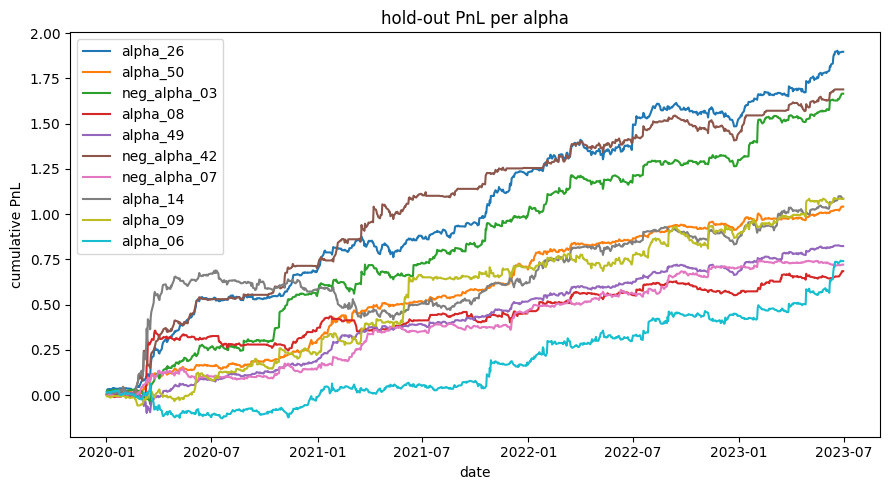

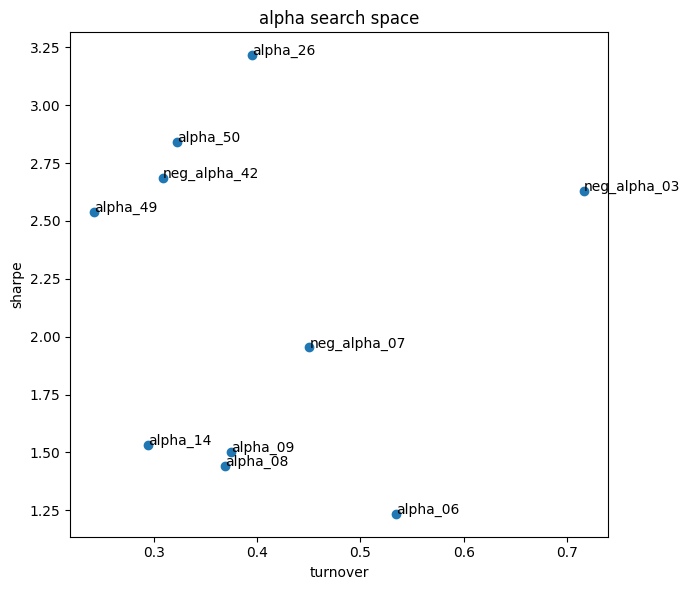

In [26]:
# =====================================================================
# FIXED 4 -- evaluate the alphas   (per alpha, then together)
# =====================================================================
# Per-alpha stats (Sharpe, total PnL, turnover, ...), the
# correlation between alphas, and the combined Sharpe of the best
# un-correlated set -- exactly what the grader does on its hidden
# period.

kpi_table = toolkit.compute_kpis(positions, forward_returns)
print("per-alpha stats:\n", kpi_table.round(4))

print("\nPnL correlation:\n",
      toolkit.pnl_correlation(alphas).round(2))

kept = toolkit.select_uncorrelated(alphas, max_corr=0.5)
print("\nun-alike alphas kept:", kept)
print("combined Sharpe (kept):",
      round(toolkit.combined_sharpe(alphas, kept), 4))

# See the curves while developing (does not affect grading).
toolkit.plot_pnl(alphas, "hold-out PnL per alpha")
toolkit.plot_kpis(kpi_table)

In [27]:
# =====================================================================
# CHECK FINAL VALID ALPHAS
# =====================================================================

import itertools

# Keep only alphas satisfying the individual requirements
valid_names = [
    name for name in kpi_table.index
    if kpi_table.loc[name, "sharpe"] > 1.2
    and kpi_table.loc[name, "turnover"] < 0.8
]

print("Individually valid alphas:", len(valid_names))
print(valid_names)

# Correlation only between valid alphas
corr = toolkit.pnl_correlation(
    {name: alphas[name] for name in valid_names}
)

print("\nCorrelation between valid alphas:")
print(corr.round(2).to_string())


# =====================================================================
# Find the largest group where every pair has correlation <= 0.5
# =====================================================================

best_group = []

for r in range(len(valid_names), 0, -1):

    found = False

    for combo in itertools.combinations(valid_names, r):

        ok = True

        for a, b in itertools.combinations(combo, 2):

            if corr.loc[a, b] > 0.5:
                ok = False
                break

        if ok:
            best_group = list(combo)
            found = True
            break

    if found:
        break


print("\n" + "=" * 60)
print("BEST VALID UNCORRELATED GROUP")
print("=" * 60)

print("Number of alphas:", len(best_group))
print("Alphas:", best_group)

if best_group:
    print(
        "Combined Sharpe:",
        round(toolkit.combined_sharpe(alphas, best_group), 4)
    )

    print("\nStats:")
    print(kpi_table.loc[best_group].round(4))

Individually valid alphas: 10
['alpha_26', 'alpha_50', 'neg_alpha_42', 'neg_alpha_03', 'alpha_49', 'neg_alpha_07', 'alpha_14', 'alpha_09', 'alpha_08', 'alpha_06']

Correlation between valid alphas:
              alpha_26  alpha_50  neg_alpha_42  neg_alpha_03  alpha_49  neg_alpha_07  alpha_14  alpha_09  alpha_08  alpha_06
alpha_26          1.00      0.44          0.49          0.47      0.48          0.03      0.40      0.28      0.25      0.21
alpha_50          0.44      1.00          0.36          0.25      0.37          0.26      0.40      0.24      0.30      0.25
neg_alpha_42      0.49      0.36          1.00          0.41      0.23          0.11      0.49      0.32      0.12      0.03
neg_alpha_03      0.47      0.25          0.41          1.00      0.43          0.18      0.16      0.15      0.09     -0.00
alpha_49          0.48      0.37          0.23          0.43      1.00          0.25      0.01      0.18      0.01     -0.04
neg_alpha_07      0.03      0.26          0.11      

In [28]:
# =====================================================================
# FINAL PRE-SUBMISSION CHECK
# =====================================================================

print("Final number of alphas:", len(kept))
print("Final alphas:", kept)

assert len(kept) >= 10, "Need at least 10 alphas"

for name in kept:
    assert name in trained, f"Missing model: {name}"
    assert name in feature_sets, f"Missing features: {name}"

final_kpis = toolkit.compute_kpis(positions, forward_returns.loc[is_test])

assert (final_kpis.loc[kept, "sharpe"] > 1.2).all(), "Sharpe condition failed"
assert (final_kpis.loc[kept, "turnover"] < 0.8).all(), "Turnover condition failed"

corr = toolkit.pnl_correlation({name: alphas[name] for name in kept})

for i, a in enumerate(kept):
    for b in kept[i+1:]:
        assert corr.loc[a, b] <= 0.5, f"Correlation failed: {a}, {b}"

print("ALL FINAL CHECKS PASSED ✅")
print(final_kpis.loc[kept, ["sharpe", "turnover"]].round(4))

Final number of alphas: 10
Final alphas: ['alpha_26', 'alpha_50', 'neg_alpha_42', 'neg_alpha_03', 'alpha_49', 'neg_alpha_07', 'alpha_14', 'alpha_09', 'alpha_08', 'alpha_06']
ALL FINAL CHECKS PASSED ✅
              sharpe  turnover
alpha_26      3.2160    0.3955
alpha_50      2.8431    0.3228
neg_alpha_42  2.6856    0.3089
neg_alpha_03  2.6307    0.7160
alpha_49      2.5390    0.2428
neg_alpha_07  1.9537    0.4507
alpha_14      1.5322    0.2944
alpha_09      1.5011    0.3745
alpha_08      1.4408    0.3693
alpha_06      1.2346    0.5345


In [29]:
# =====================================================================
# FIX TOOLKIT MODULE NAME BEFORE SAVING
# =====================================================================

import shutil
import importlib

# Create the correctly named toolkit file
shutil.copy("financial_toolkit.py", "finance_toolkit.py")

# Import it under the name expected by the assignment
finance_toolkit = importlib.import_module("finance_toolkit")

# Change each model's top-level class to the equivalent class
# from finance_toolkit. We keep all trained weights unchanged.
for name in kept:
    model = trained[name]

    class_name = model.__class__.__name__
    correct_class = getattr(finance_toolkit, class_name)

    model.__class__ = correct_class

    print(
        name,
        "->",
        model.__class__.__module__,
        model.__class__.__name__
    )

print("\nModule conversion finished ✅")

alpha_26 -> finance_toolkit MLP
alpha_50 -> finance_toolkit LSTM
neg_alpha_42 -> finance_toolkit MLP
neg_alpha_03 -> finance_toolkit MLP
alpha_49 -> finance_toolkit LSTM
neg_alpha_07 -> finance_toolkit MLP
alpha_14 -> finance_toolkit MLP
alpha_09 -> finance_toolkit MLP
alpha_08 -> finance_toolkit MLP
alpha_06 -> finance_toolkit MLP

Module conversion finished ✅


In [30]:
for name in kept:
    assert trained[name].__class__.__module__ == "finance_toolkit"

print("ALL 10 MODELS USE finance_toolkit ✅")

ALL 10 MODELS USE finance_toolkit ✅


In [31]:
# =====================================================================
# FIXED 5 -- write the submission
# =====================================================================
# For every kept alpha, save two things: the trained model and the
# list of feature names it used.  Submit this folder together with
# your notebook (your feature definitions live in the notebook).
SUBMISSION_DIR = "../output"
os.makedirs(SUBMISSION_DIR, exist_ok=True)

for i in kept:
    torch.save(trained[i], os.path.join(SUBMISSION_DIR, "model_%s.pt" % i))

params = {
    "alphas": kept,
    "feature_sets": {i: feature_sets[i] for i in kept},
}
with open(os.path.join(SUBMISSION_DIR, "params.json"), "w") as handle:
    json.dump(params, handle, indent=2)

print("submission written to", os.path.abspath(SUBMISSION_DIR))

submission written to /output


In [32]:
import os

files = sorted(os.listdir("/output"))

print("Files in /output:")
for f in files:
    print("-", f)

print("\nTotal files:", len(files))

Files in /output:
- model_alpha_06.pt
- model_alpha_08.pt
- model_alpha_09.pt
- model_alpha_14.pt
- model_alpha_26.pt
- model_alpha_49.pt
- model_alpha_50.pt
- model_neg_alpha_03.pt
- model_neg_alpha_07.pt
- model_neg_alpha_42.pt
- params.json

Total files: 11


In [33]:
import shutil

shutil.make_archive("/content/submission", "zip", "/output")

print("ZIP created: /content/submission.zip")

ZIP created: /content/submission.zip
